In [1]:
import pandas as pd, matplotlib.pyplot as plt, seaborn as sns 
from scipy import stats

url = "https://raw.githubusercontent.com/nkmwicz/worldcup2018data/refs/heads/main/cleaned_events_world_cup2018.csv"

df = pd.read_csv(url)
df.head(1)

,eventId,subEventName,tags,playerId,matchId,eventName,teamId,matchPeriod,eventSec,subEventId,id,x1,y1,x2,y2
0,8,Simple pass,['Accurate'],Mohammad Ibrahim Al Sahlawi,"Russia - Saudi Arabia, 5 - 0",Pass,Saudi Arabia,1H,1.656214,Simple pass,258612104,50,50,35.0,53.0


In [2]:
df['subEventName'].unique()


<StringArray>
[            'Simple pass',               'High pass',
                'Air duel',   'Ground attacking duel',
   'Ground defending duel',                'Throw in',
                    'Foul',               'Free Kick',
               'Clearance',                   'Touch',
  'Ground loose ball duel',                  'Corner',
               'Head pass',                  'Launch',
            'Acceleration',                    'Shot',
              'Smart pass',                   'Cross',
                'Reflexes',                       nan,
               'Hand pass',               'Goal kick',
         'Free kick cross',               'Hand foul',
            'Save attempt',          'Free kick shot',
 'Goalkeeper leaving line',                 'Penalty',
          'Late card foul',            'Violent Foul',
                 'Protest',        'Out of game foul',
          'Time lost foul',              'Simulation']
Length: 34, dtype: str

In [3]:
df['eventName'].unique()

<StringArray>
[                   'Pass',                    'Duel',
               'Free Kick',                    'Foul',
      'Others on the ball',                    'Shot',
            'Save attempt',                 'Offside',
 'Goalkeeper leaving line']
Length: 9, dtype: str

In [4]:
df['tags'].unique()

<StringArray>
[                                                                              '['Accurate']',
                                                                        '['Won', 'Accurate']',
                                                                   '['Lost', 'Not accurate']',
                                                    '['Free space right', 'Won', 'Accurate']',
                                                   '['Take on right', 'Neutral', 'Accurate']',
                                                    '['Take on left', 'Neutral', 'Accurate']',
                                                '['Free space left', 'Lost', 'Not accurate']',
                                                                           '['Not accurate']',
                                                       '['Take on right', 'Won', 'Accurate']',
                                                   '['Take on left', 'Lost', 'Not accurate']',
 ...
                               

In [5]:
import ast

df['tags'] = df['tags'].apply(ast.literal_eval)

In [8]:
unique_tags = list({tag for lst in df['tags'] for tag in lst}) #curly brackets make a set
unique_tags

['Position: Out center right',
 'Position: Out high left',
 'Position: Goal center left',
 'Position: Goal low left',
 'Position: Goal center right',
 'Position: Post low left',
 'Not accurate',
 'Direct',
 'Free space right',
 'Indirect',
 'Counter attack',
 'Position: Goal high left',
 'Left foot',
 'Key pass',
 'Missed ball',
 'Lost',
 'Dangerous ball lost',
 'Right foot',
 'Fairplay',
 'Goal',
 'Blocked',
 'Position: Goal high center',
 'Position: Post low right',
 'Yellow card',
 'Accurate',
 'Position: Post high left',
 'Won',
 'Neutral',
 'Take on right',
 'Position: Post center right',
 'Position: Post high right',
 'Position: Out high center',
 'Through',
 'Head/body',
 'Anticipated',
 'Position: Out high right',
 'Position: Goal high right',
 'Feint',
 'Red card',
 'Assist',
 'Position: Out low left',
 'Own goal',
 'Position: Out low right',
 'Opportunity',
 'Free space left',
 'Position: Goal center',
 'Position: Out center left',
 'Position: Post high center',
 'Second yell

In [9]:
df['is_pass'] = (df['eventName'] =='Pass').astype(int)
df['is_shot'] = (df['eventName'] =='Shot').astype(int)

In [14]:
df['is_acc_pass'] = df.apply(lambda row: (row['is_pass'] == 1) and ('Accurate' in row['tags']), axis = 1).astype(int)
df['is_goal'] = df.apply(lambda row: (row['is_shot'] == 1) and ('Goal' in row['tags']), axis = 1).astype(int)

df.head(1)

#lambda is an anonymous function
# used to filter out what is accurate pass? 

,eventId,subEventName,tags,playerId,matchId,eventName,teamId,matchPeriod,eventSec,subEventId,id,x1,y1,x2,y2,is_pass,is_shot,is_acc_pass,is_acc_shot,is_goal
0,8,Simple pass,[Accurate],Mohammad Ibrahim Al Sahlawi,"Russia - Saudi Arabia, 5 - 0",Pass,Saudi Arabia,1H,1.656214,Simple pass,258612104,50,50,35.0,53.0,1,0,1,0,0


In [22]:
grp_df = df.groupby(['teamId', 'matchId']).agg(
    passes =('is_pass', 'sum'),
    acc_passes=('is_acc_pass', 'sum'),
    shots=('is_shot', 'sum'),
    goals=('is_goal', 'sum'),
).reset_index()

grp_df


,teamId,matchId,passes,acc_passes,shots,goals
0,Argentina,"Argentina - Croatia, 0 - 3",476,393,10,0
1,Argentina,"Argentina - Iceland, 1 - 1",744,675,22,1
2,Argentina,"France - Argentina, 4 - 3",486,420,9,3
3,Argentina,"Nigeria - Argentina, 1 - 2",545,458,6,2
4,Australia,"Australia - Peru, 0 - 2",512,446,11,0
...,...,...,...,...,...,...
123,Uruguay,"Egypt - Uruguay, 0 - 1",579,499,11,1
124,Uruguay,"Uruguay - France, 0 - 2",304,227,9,0
125,Uruguay,"Uruguay - Portugal, 2 - 1",238,185,6,2
126,Uruguay,"Uruguay - Russia, 3 - 0",466,405,12,1


Text(0.5, 0.98, 'good stuff')

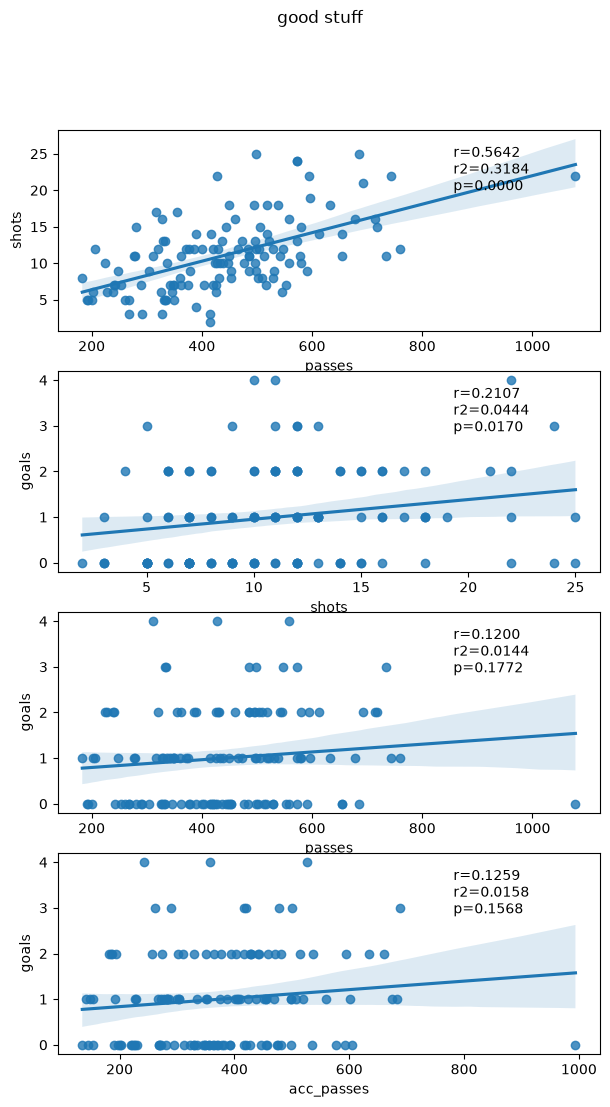

In [26]:
# vars = [(ind, dep)]
vars = [
    ('passes', 'shots'),
    ('shots', 'goals'),
    ('passes', 'goals'),
    ('acc_passes', 'goals'),
]

fig, axes = plt.subplots(nrows=4, figsize=(7, 12))

for idx, (ind, dep) in enumerate(vars):
    ax = axes[idx]
    r, p = stats.pearsonr(grp_df[ind], grp_df[dep])
    r2 = r**2
    text = f"""
    r={r:.4f}
    r2={r2:.4f}
    p={p:.4f}"""
    regplot = sns.regplot(data =grp_df, x= ind, y= dep, ax=ax)
    ax.text(.7, .7, text, transform=regplot.transAxes)
    
fig.suptitle('good stuff')    

# never wanna hardcode anything